# Paper Figures: Figure S1 - Movement Analysis (legacy)

This notebook generates publication-ready figures for the Bazzino & Roitman sodium appetite manuscript using data assembled by `src/assemble_all_data.py`.

**Figure 1: Behavioral Analysis** — Movement analysis showing heatmaps and summary plots for replete and deplete conditions across sodium concentrations.

In [1]:
from pathlib import Path
import sys
# Add src to path for importing local modules
sys.path.insert(0, str(Path("../src").resolve()))
from data_io import load_assembled

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import seaborn as sns
from scipy import stats
from extract_behav_parameters import smooth_array



from figure_config import (
    configure_matplotlib,
    COLORS,
    HEATMAP_CMAP_DIV,
    HEATMAP_CMAP_RED,
    HEATMAP_CMAP_BLUE,
    DATAFOLDER,
    FIGSFOLDER,
    BEHAV_SMOOTH_WINDOW,
    SAVE_FIGS,
)
from figure_plotting import (
    smooth_array,
    get_heatmap_data,
    get_mean_snips,
    get_auc,
    init_heatmap_figure,
    init_snips_figure,
    make_heatmap,
    plot_snips,
    save_figure_atomic,
    calculate_ylims,
)

# Configure matplotlib
configure_matplotlib()
colors = COLORS  # Use shared color palette
custom_cmap_red = HEATMAP_CMAP_RED  # Use shared colormap
custom_cmap_blue = HEATMAP_CMAP_BLUE  # Use shared colormap

custom_cmap = HEATMAP_CMAP_DIV  # Use shared colormap

SAVE_FIGS = False

## Load Assembled Data

Load the complete dataset from the pickle file generated by the assembly script.

In [2]:
assembled_data_path = DATAFOLDER / "assembled"

data = load_assembled(assembled_data_path)

# Extract main components
x_array = data["x_array"]
snips_photo = data["snips_photo"]
snips_movement = data["snips_movement"]
snips_angvel = data["snips_angvel"]

fits_df = data["fits_df"]
params = data.get("params", {})
metadata = data.get("metadata", {})

print("Loaded assembled data from data/assembled")
print(f"\nData structure:")
print(f"  - x_array shape: {x_array.shape}")
print(f"  - snips_photo shape: {snips_photo.shape}")
print(f"  - snips_angvel shape: {snips_angvel.shape}")
print(f"  - snips_movement shape: {snips_movement.shape}")
print(f"  - x_array columns: {x_array.columns.tolist()}")
print(f"  - Number of trials: {len(x_array)}")

Loaded assembled data from data/assembled

Data structure:
  - x_array shape: (1960, 30)
  - snips_photo shape: (1960, 200)
  - snips_angvel shape: (1960, 200)
  - snips_movement shape: (1960, 200)
  - x_array columns: ['trial', 'id', 'condition', 'infusiontype', 'sex', 'movement_mean', 'movement_std', 'angvel_mean', 'angvel_std', 'simba_raw_mean', 'simba_zscore_mean', 'simba_median_balance', 'simba_median_balance_binarized', 'simba_median_balance_quantized', 'cluster_photo', 'clusterness_photo', 'euclidean_diff', 'auc_snips', 'auc_snips_early', 'auc_snips_late', 'auc_movement', 'auc_angvel', 'time_moving', 'time_above_angvel_threshold', 'time_moving_raw', 'realigned_trials_da', 'realigned_trials_da_velocity', 'realigned_trials_da_cluster', 'realigned_trials_behav', 'trial_aligned']
  - Number of trials: 1960


## Figure 1: Behavioral Analysis — Movement Metrics

Analysis of behavioral responses (movement) showing heatmaps, snip time series, and summary AUC metrics across replete and deplete sodium conditions, separated by infusion type (10NaCl vs 45NaCl).

In [3]:
def zscore_to_entire_session(snips, x_array, param_name):

    mean = x_array[param_name + "_mean"].values
    std = x_array[param_name + "_std"].values
    snips_zscored = (snips - mean[:, np.newaxis]) / std[:, np.newaxis]

    return snips_zscored

In [4]:
# Smoothing angvel data and zscoring for plotting
snips_angvel_smoothed = smooth_array(snips_angvel, window_size=BEHAV_SMOOTH_WINDOW)
# snips_angvel_zscored = zscore(snips_angvel_smoothed, baseline_points=50)
# snips_angvel_zscored = zscore_to_entire_session(snips_angvel, x_array, "angvel")  # Z-score using entire session stats
# snips_angvel_smoothed = smooth_array(snips_angvel_zscored, window_size=BEHAV_SMOOTH_WINDOW)
snips_to_plot = np.array(snips_movement)  # Use smoothed and z-scored data for all subsequent analyses and plotting

# Parameters for visualization - MOVEMENT
# Use dynamic scaling based on actual data ranges (asymmetric, not symmetric)
# This ensures heatmaps use the full range of your data without artificial symmetry
vmin = np.nanpercentile(snips_movement, 5)  # 5th percentile for lower bound
vmax = np.nanpercentile(snips_movement, 95)  # 95th percentile for upper bound
vlim = (vmin, vmax)
print(f"Calculated asymmetric vlims: vmin={vmin:.4f}, vmax={vmax:.4f}")
# vlim = (-0.75, 0.75) # for zscored data
vlim = (1, 6)

# Calculate dynamic y-limits based on all snips data - MOVEMENT
print("\n" + "="*60)
print("CALCULATING Y-LIMITS FOR TIME SERIES PLOTS")
print("="*60)

# Get all condition/infusion combinations to compute limits
rep_10, rep_45 = get_mean_snips(snips_movement, x_array, "replete")
dep_10, dep_45 = get_mean_snips(snips_movement, x_array, "deplete")

# Calculate y-limits based on all snips with 5% padding
calc_ylims = calculate_ylims([rep_10, rep_45, dep_10, dep_45], pad_percentage=5)

print(f"  Data range (min, max): ({np.nanmin(snips_movement):.4f}, {np.nanmax(snips_movement):.4f})")
print(f"  Calculated y-limits: {calc_ylims}")
print("="*60 + "\n")

# Use calculated limits or override with fixed values if preferred
ylims = calc_ylims
ylims = (0, 8)

Calculated asymmetric vlims: vmin=0.6249, vmax=11.6887

CALCULATING Y-LIMITS FOR TIME SERIES PLOTS
  Data range (min, max): (0.1945, 372.4277)
  Calculated y-limits: (np.float64(0.25943394567546385), np.float64(14.322430746004098))



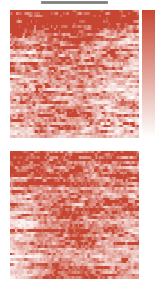

In [5]:
### 1A. Heatmaps — Replete Condition

f, ax1, ax2, cbar_ax = init_heatmap_figure()

# Replete + 10NaCl
heatmap_data_rep_10 = get_heatmap_data(snips_to_plot, x_array, "replete", "10NaCl")
replete_10_auc = get_auc(heatmap_data_rep_10)
make_heatmap(heatmap_data_rep_10, ax1, vlim, inf_bar=True, cmap=custom_cmap_red)

# Replete + 45NaCl
heatmap_data_rep_45 = get_heatmap_data(snips_to_plot, x_array, "replete", "45NaCl")
replete_45_auc = get_auc(heatmap_data_rep_45)
make_heatmap(heatmap_data_rep_45, ax2, vlim, cbar_ax=cbar_ax, cmap=custom_cmap_red)

if SAVE_FIGS:
    save_figure_atomic(f, "figS1_heatmap_movement_replete", FIGSFOLDER)

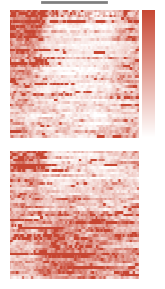

In [6]:
### 1B. Heatmaps — Deplete Condition

f, ax1, ax2, cbar_ax = init_heatmap_figure()

# Deplete + 10NaCl
heatmap_data_dep_10 = get_heatmap_data(snips_to_plot, x_array, "deplete", "10NaCl")
deplete_10_auc = get_auc(heatmap_data_dep_10)
make_heatmap(heatmap_data_dep_10, ax1, vlim, inf_bar=True, cmap=custom_cmap_red)

# Deplete + 45NaCl
heatmap_data_dep_45 = get_heatmap_data(snips_to_plot, x_array, "deplete", "45NaCl")
deplete_45_auc = get_auc(heatmap_data_dep_45)
make_heatmap(heatmap_data_dep_45, ax2, vlim, cbar_ax=cbar_ax, cmap=custom_cmap_red)

if SAVE_FIGS:
    save_figure_atomic(f, "figS1_heatmap_movement_deplete", FIGSFOLDER)

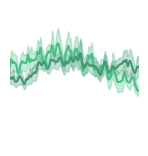

In [7]:
### 1C. Time Series Snips — Replete Condition

# Get animal-averaged snips for replete
snips_rep_10, snips_rep_45 = get_mean_snips(snips_to_plot, x_array, "replete")

f, ax = init_snips_figure()
plot_snips(snips_rep_10, snips_rep_45, ax, colors[0], colors[1], ylims)

if SAVE_FIGS:
    save_figure_atomic(f, "figS1_snips_movement_replete", FIGSFOLDER)

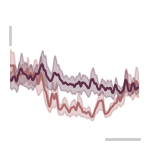

In [8]:
### 1D. Time Series Snips — Deplete Condition

# Get animal-averaged snips for deplete
snips_dep_10, snips_dep_45 = get_mean_snips(snips_to_plot, x_array, "deplete")

f, ax = init_snips_figure()
plot_snips(snips_dep_10, snips_dep_45, ax, colors[2], colors[3], ylims, yscalebar=[6,7], xscalebar=True)

if SAVE_FIGS:
    save_figure_atomic(f, "figS1_snips_movement_deplete", FIGSFOLDER)

In [9]:
from assemble_shap_dfs import assemble_shap_dfs

DATAFOLDER = Path("../data/shap_values")
df_shap, df_shap_raw, feature_summary = assemble_shap_dfs(DATAFOLDER)

In [10]:
feature_summary

,feature,mean_shap,importance,variability,mean_shap_appetitive,mean_shap_non_appetitive,raw_mean,raw_sd,raw_min,raw_max,...,class_difference,signed_importance,group,bodypart,timewindow,reverse_coded,aligned_signed_importance,display_group,cumulative_importance,reverse_cumulative_importance
0,Total_movement_M1_mean_10,0.005214,0.014481,0.016180,0.017726,-0.007299,7.596502,11.718850,0.193900,117.094597,...,0.025026,-0.014481,movement,whole rat,10,False,-0.014481,movement,0.033933,9.660667e-01
1,Total_movement_M1_mean_10_percentile_rank,0.007377,0.014088,0.016186,0.020256,-0.005501,2.800796,11.598030,-106.194603,12.291800,...,0.025757,0.014088,movement,whole rat,10,True,-0.014088,"movement, reverse coded",0.066946,9.330540e-01
2,Total_movement_M1_sum_10,0.005153,0.013934,0.015545,0.017296,-0.006991,75.965021,117.188490,1.939300,1170.946167,...,0.024288,-0.013934,movement,whole rat,10,False,-0.013934,movement,0.099599,9.004015e-01
3,Head_base_movement_M1_mean_10,0.005090,0.012353,0.013405,0.015754,-0.005574,1.331906,2.133838,0.000000,19.008600,...,0.021328,-0.012353,movement,head base,10,False,-0.012353,movement,0.128547,8.714534e-01
4,Head_base_movement_M1_sum_10,0.004991,0.011776,0.012701,0.015203,-0.005222,13.319071,21.338366,0.000000,190.085800,...,0.020425,-0.011776,movement,head base,10,False,-0.011776,movement,0.156142,8.438575e-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
148,Movement_mouse_nose,0.000713,0.000838,0.001036,0.001263,0.000162,1.891705,3.166628,0.000000,25.100100,...,0.001101,0.000838,movement,nose,none,False,0.000838,movement,0.993653,6.346736e-03
149,Tail_base_movement_M1_median_2,0.000552,0.000708,0.001020,0.000946,0.000158,1.174918,5.644485,0.000000,74.922997,...,0.000789,0.000708,movement,tail base,2,False,0.000708,movement,0.995311,4.688798e-03
150,Tail_base_movement_M1_sum_2,0.000556,0.000707,0.001035,0.000959,0.000153,2.349835,11.288970,0.000000,149.846100,...,0.000807,0.000707,movement,tail base,2,False,0.000707,movement,0.996969,3.031426e-03
151,Tail_base_movement_M1_mean_2,0.000546,0.000694,0.001017,0.000937,0.000156,1.174918,5.644485,0.000000,74.922997,...,0.000781,0.000694,movement,tail base,2,False,0.000694,movement,0.998595,1.405267e-03


In [11]:
# set colours for strips

bodypart_colors = {
    "nose": "#d95f02",
    "tail base": "#1b9e77",
    "head base": "#7570b3",
    "ears": "#e7298a",
    "whole rat": "#a6761d",
    "other": "#bdbdbd",
}
bodypart_codes = {name: code for code, name in enumerate(bodypart_colors)}
bodypart_values = feature_summary["bodypart"].map(bodypart_codes).to_numpy()

window_order = ["none", "2", "5", "6", "7.5", "10"]
window_colors = ["#d9d9d9", "#440154", "#31688e", "#35b779", "#90d743", "#fde725"]
window_codes = {name: code for code, name in enumerate(window_order)}
window_values = feature_summary["timewindow"].map(window_codes).to_numpy()  # unchanged

# window sizes are frame counts at 10 fps; 7.5 is truncated to 7 frames by the extractor
window_seconds = {"none": "none", "2": "0.2 s", "5": "0.5 s", "6": "0.6 s", "7.5": "0.7 s", "10": "1.0 s"}

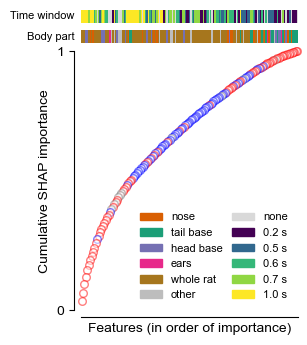

In [12]:
f, [ax_window, ax_bp, ax] = plt.subplots(
    figsize=(3.1, 3.8),
    nrows=3,
    sharex=True,
    gridspec_kw={"height_ratios": [0.05, 0.05, 1], "hspace": 0.08,
                 "left": 0.2, "top": 0.9},
)

ax_bp.imshow(
    bodypart_values[None, ::-1],
    aspect="auto",
    interpolation="none",
    cmap=ListedColormap(list(bodypart_colors.values())),
    vmin=-0.5,
    vmax=len(bodypart_colors) - 0.5,
)
ax_window.imshow(
    window_values[None, ::-1],
    aspect="auto",
    interpolation="none",
    cmap=ListedColormap(window_colors),
    vmin=-0.5,
    vmax=len(window_order) - 0.5,
)

ax_window.text(-0.03, 0.5, "Time window", va="center", ha="right", fontsize=8, transform=ax_window.transAxes)
ax_bp.text(-0.03, 0.5, "Body part", va="center", ha="right", fontsize=8, transform=ax_bp.transAxes)

for axis in [ax_bp, ax_window]:
    axis.set_xticks([])
    axis.set_yticks([])
    axis.set_ylim(-0.5, 0.5)
    axis.set_xlim(len(feature_summary) - 0.5, -0.5)

for xtick, row in enumerate(feature_summary.iloc[::-1].itertuples(index=False)):
    color = {"movement": "red", "geometry": "blue"}.get(row.group, "grey")
    ax.scatter(
        xtick,
        row.cumulative_importance,
        edgecolors=color,
        facecolors="w",
        alpha=0.5,
        s=30,
        clip_on=False,
    )
    
ax.set_ylim(0, 1)
#ax.invert_yaxis()

ax.set_ylabel("Cumulative SHAP importance")

bodypart_legend = [
    Patch(color=color, label=label)
    for label, color in bodypart_colors.items()
]
bodypart_legend_artist = ax.legend(
    handles=bodypart_legend,
    loc="lower right",
    bbox_to_anchor=(0.7, 0),
    frameon=False,
    fontsize=8,
)

window_legend = [
    Patch(color=color, label=window_seconds[window])
    for window, color in zip(window_order, window_colors)
]
ax.legend(
    handles=window_legend,
    loc="lower right",
    bbox_to_anchor=(1, 0),
    frameon=False,
    fontsize=8,
)
ax.add_artist(bodypart_legend_artist)

ax.set_xlabel("Features (in order of importance)")
ax.set_yticks([0, 1], labels=["0", "1"])

sns.despine(ax=ax_bp, left=True, bottom=True)
sns.despine(ax=ax_window, left=True, bottom=True)
sns.despine(ax=ax, offset=5)
for axis in [ax1, ax_window, ax2]:
    axis.set_yticks([])
    
save_figure_atomic(f, "figS1_cumul_shap_importance", FIGSFOLDER)

In [13]:
x_array["total_movement"] = snips_movement[:,50:150].sum(axis=1)

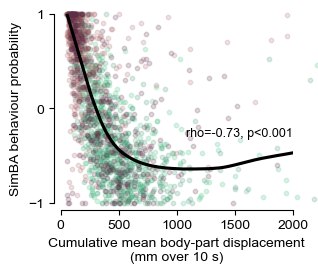

In [14]:
f, ax = plt.subplots(figsize=(3, 3),
                     gridspec_kw={"bottom": 0.25})

x = x_array["total_movement"]
y = x_array["simba_median_balance"]
rho, p = stats.spearmanr(x, y)
p_label = "p<0.001" if p < 0.001 else f"p={p:.3f}"

CORRELATION_FIT = "lowess"  # Choose: "linear", "lowess", or "none"
if CORRELATION_FIT == "linear":
    sns.regplot(x=x, y=y, ax=ax, scatter=False, ci=95,
                line_kws={"color": "k"})
elif CORRELATION_FIT == "lowess":
    sns.regplot(x=x, y=y, ax=ax, scatter=False, lowess=True, ci=95,
                line_kws={"color": "k"})
elif CORRELATION_FIT != "none":
    raise ValueError("CORRELATION_FIT must be 'linear', 'lowess', or 'none'")

for pair, color in zip([("replete", "10NaCl"), ("replete", "45NaCl"), ("deplete", "10NaCl"), ("deplete", "45NaCl")], colors):
    mask = (x_array["condition"] == pair[0]) & (x_array["infusiontype"] == pair[1])
    ax.scatter(x[mask], y[mask], color=color, s=10, alpha=0.2, label=f"{pair[0]} + {pair[1]}", clip_on=False)
# ax.scatter(x, y, color="k", s=10, alpha=0.05, clip_on=False)

ax.set_xlim(0, 2000)
ax.text(1, 0.4, f"rho={rho:.2f}, {p_label}", transform=ax.transAxes,
        color="k", fontsize=9, va="top", ha="right")

ax.set_ylim(-1, 1)
ax.set_yticks([-1, 0, 1])
ax.set_xlabel("Cumulative mean body-part displacement\n(mm over 10 s)")
ax.set_ylabel("SimBA behaviour probability")

sns.despine(offset=5)

save_figure_atomic(f, "figS1_correlation_movement_simba", FIGSFOLDER)

Pearson correlation: -0.7036876338686753 6.055996446662855e-293 p<0.001
Spearman correlation: -0.7349932259088763 0.0 p<0.001


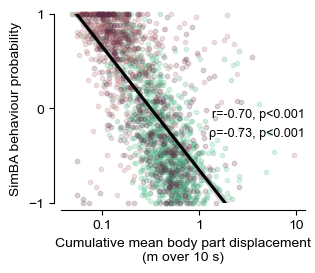

In [15]:
f, ax = plt.subplots(figsize=(3, 3),
                     gridspec_kw={"bottom": 0.25, "right": 0.94})

x = x_array["total_movement"]
y = x_array["simba_median_balance"]


x = np.log10(x)  # Apply log transformation to y-axis data

CORRELATION_FIT = "linear"  # Choose: "linear", "lowess", or "none"
if CORRELATION_FIT == "linear":
    sns.regplot(x=x, y=y, ax=ax, scatter=False, ci=95,
                line_kws={"color": "k"})
elif CORRELATION_FIT == "lowess":
    sns.regplot(x=x, y=y, ax=ax, scatter=False, lowess=True, ci=95,
                line_kws={"color": "k"})
elif CORRELATION_FIT != "none":
    raise ValueError("CORRELATION_FIT must be 'linear', 'lowess', or 'none'")

for pair, color in zip([("replete", "10NaCl"), ("replete", "45NaCl"), ("deplete", "10NaCl"), ("deplete", "45NaCl")], colors):
    mask = (x_array["condition"] == pair[0]) & (x_array["infusiontype"] == pair[1])
    ax.scatter(x[mask], y[mask], color=color, s=10, alpha=0.2, label=f"{pair[0]} + {pair[1]}", clip_on=False)

ax.set_ylim(-1, 1)
ax.set_yticks([-1, 0, 1])
ax.set_xlabel("Cumulative mean body part displacement\n(m over 10 s)")
ax.set_ylabel("SimBA behaviour probability")

# ax.set_xlim(0, 2000)
ax.set_xticks([2, 3, 4], labels=["0.1", "1", "10"])  # Set x-ticks for log scale

sns.despine(offset=5)


r, p = stats.pearsonr(x, y)
p_label = "p<0.001" if p < 0.001 else f"p={p:.3f}"
print("Pearson correlation:", r, p, p_label)

rho, p = stats.spearmanr(x, y)
p_label_spearman = "p<0.001" if p < 0.001 else f"p={p:.3f}"
print("Spearman correlation:", rho, p, p_label_spearman)

ax.text(1, 0.5, f"r={r:.2f}, {p_label}", transform=ax.transAxes,
        color="k", fontsize=9, va="top", ha="right")

ax.text(1, 0.4, f"ρ={rho:.2f}, {p_label_spearman}", transform=ax.transAxes,
        color="k", fontsize=9, va="top", ha="right")

save_figure_atomic(f, "figS1_correlation_movement_simba_logaxis", FIGSFOLDER)